# Texas Senate prices: Kalshi and Polymarket

We automate downloading one week of minute-level prices, aligning the two sources,
comparing Democratic and Republican party contracts, and exporting the results.
Our question is how the recorded prices differ across platforms and how often the price of a Democratic/Republican pair is below $1.


## Data access and contract definitions

Access review, 29 October 2026: the [Kalshi documentation](https://docs.kalshi.com/getting_started/quick_start_market_data)
and [Polymarket documentation](https://docs.polymarket.com/market-data/discover-markets)
describe public market-data access without authentication. We use these API
interfaces to request event metadata and price history.

[Polymarket's robots.txt](https://polymarket.com/robots.txt) is almsot empty with no rules.
[Kalshi's robots.txt](https://kalshi.com/robots.txt) disallows LLM scrapers, but we're using their API so problem.


The selected markets describe **parties**, even when the website shows a candidate's name:

| Price column | Selected YES contract |
|---|---|
| `kalshi_democratic` | `SENATETX-26-D`: Democratic party |
| `kalshi_republican` | `SENATETX-26-R`: Republican party |
| `polymarket_democratic` | `will-the-democrats-win-the-texas-senate-race-in-2026` |
| `polymarket_republican` | `will-the-republicans-win-the-texas-senate-race-in-2026` |

Both sources concern the 2026 Texas U.S. Senate race, but their settlement wording
differs. [Kalshi's market rules](https://kalshi.com/markets/senatetx/texas-senate-race/senatetx-26)
refer to a party representative being sworn in for the term beginning in 2027,
with accelerated determination possible after media projections.
[Polymarket's contract descriptions](https://gamma-api.polymarket.com/events/slug/texas-senate-election-winner)
refer to the election winner, including run-offs, using agreement among AP, Fox News,
and NBC or official certification. The party contract also follows a replacement nominee.

We compare historical prices for these related outcomes. A sum below $1 is a
flagged observation: settlement differences, other-party outcomes, fees, and
available buy quotes are outside this calculation. We do not treat such a flag
as a verified executable arbitrage.


In [ ]:
#Packages
import json
import textwrap
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import pandas as pd
import numpy as np

#API and event information
DAYS = 7
KALSHI_EVENT = "SENATETX-26"
POLYMARKET_EVENT = "texas-senate-election-winner"
KALSHI_BASE = "https://external-api.kalshi.com/trade-api/v2"
POLYMARKET_BASE = "https://data-api.polymarket.com/v2"

#Labels and column names
PRICE_COLUMNS = [
    "kalshi_democratic", "kalshi_republican",
    "polymarket_democratic", "polymarket_republican",
]
POLYMARKET_COLUMNS = ["polymarket_democratic", "polymarket_republican"]
SUM_COLUMNS = [
    "sum_kalshi", "sum_polymarket",
    "sum_kalshi_r_poly_d", "sum_poly_r_kalshi_d",
]
DELTA_COLUMNS = ["delta_republican", "delta_democratic"]

LABELS = {
    "kalshi_democratic": "Kalshi: Democratic",
    "kalshi_republican": "Kalshi: Republican",
    "polymarket_democratic": "Polymarket: Democratic",
    "polymarket_republican": "Polymarket: Republican",
    "sum_kalshi": "Kalshi R + Kalshi D",
    "sum_polymarket": "Polymarket R + Polymarket D",
    "sum_kalshi_r_poly_d": "Kalshi R + Polymarket D",
    "sum_poly_r_kalshi_d": "Polymarket R + Kalshi D",
    "delta_republican": "Republican: Kalshi - Polymarket",
    "delta_democratic": "Democratic: Kalshi - Polymarket",
}


## Downloading and aligning prices

In [ ]:
#Makes one request and parses the response. 
def get_json(url, params=None):
    if params:
        url += "?" + urlencode(params)
    headers = {
        "Accept": "application/json",
        "User-Agent": "texas-senate-price-history/1.0",
    }
    with urlopen(Request(url, headers=headers), timeout=45) as response:
        return json.load(response)

#Converts observations to UTC minute ends.
def minute_series(rows, start, end):
    frame = pd.DataFrame(rows, columns=["timestamp", "price", "resolution_seconds"])
    frame["price"] = pd.to_numeric(frame["price"], errors="coerce")
    frame = frame.dropna(subset=["price"])
    frame = frame.sort_values("timestamp", kind="stable")
    observed = pd.to_datetime(frame["timestamp"], unit="s", utc=True)
    available = observed + pd.to_timedelta(frame["resolution_seconds"], unit="s")
    frame["time"] = available.dt.ceil("min")
    window = (frame["time"] > start) & (frame["time"] <= end)
    frame = frame.loc[window].drop_duplicates("time", keep="last")
    frame = frame.set_index("time")
    return frame["price"].astype(float).sort_index()

#Collect Kalshi data for number of days, using 1-day requests to avoid rate limits. 
#The API returns the last price of each minute, but some minutes may be missing. 
#The function returns a DataFrame with a UTC datetime index and a single column of prices.
def fetch_kalshi(start, end):
    event = get_json(f"{KALSHI_BASE}/events/{KALSHI_EVENT}")
    series = event["event"]["series_ticker"]
    tickers = {
        f"{KALSHI_EVENT}-D": "kalshi_democratic",
        f"{KALSHI_EVENT}-R": "kalshi_republican",
    }
    rows = {name: [] for name in tickers.values()}
    left, finish = int(start.timestamp()), int(end.timestamp())
    while left < finish:
        right = min(left + 86400, finish)
        url = f"{KALSHI_BASE}/series/{series}/events/{KALSHI_EVENT}/candlesticks"
        params = {"start_ts": left + 1, "end_ts": right, "period_interval": 1}
        data = get_json(url, params)
        right = min(right, int(data.get("adjusted_end_ts") or right))
        for ticker, candles in zip(data["market_tickers"], data["market_candlesticks"]):
            if ticker not in tickers:
                continue
            for candle in candles:
                timestamp = int(candle["end_period_ts"])
                if left < timestamp <= right:
                    prices = candle.get("price") or {}
                    value = prices.get("close_dollars")
                    if value is None or value == "":
                        value = prices.get("previous_dollars")
                    rows[tickers[ticker]].append((timestamp, value, 0))
        left = right
    return {name: minute_series(points, start, end) for name, points in rows.items()}

#Collect Polymarket data for 1 week, using 12-hour requests to avoid rate limits.
#The API returns the last price of each minute, but some minutes may be missing.
def fetch_polymarket(start, end):
    event = get_json("https://gamma-api.polymarket.com/events/slug/" + POLYMARKET_EVENT)
    targets = {
        "will-the-democrats-win-the-texas-senate-race-in-2026": "polymarket_democratic",
        "will-the-republicans-win-the-texas-senate-race-in-2026": "polymarket_republican",
    }
    result = {}
    begin, finish = int(start.timestamp()), int(end.timestamp())
    for market in event["markets"]:
        if market.get("slug") not in targets:
            continue
        outcomes, tokens = market["outcomes"], market["clobTokenIds"]
        if isinstance(outcomes, str):
            outcomes = json.loads(outcomes)
        if isinstance(tokens, str):
            tokens = json.loads(tokens)
        outcomes = [outcome.lower() for outcome in outcomes]
        token_id = str(tokens[outcomes.index("yes")])
        points = {}
        for left in range(begin, finish, 12 * 3600):
            params = {
                "token_id": token_id, "start": left,
                "end": min(left + 12 * 3600, finish),
                "bucket_seconds": 60, "limit": 10000,
            }
            while True:
                page = get_json(f"{POLYMARKET_BASE}/prices-history", params)
                for point in page["data"]:
                    timestamp = int(point["timestamp"])
                    resolution = int(point["resolution_seconds"])
                    if begin <= timestamp < finish:
                        key = (timestamp, resolution)
                        points[key] = (timestamp, point["price"], resolution)
                cursor = page["pagination"]["next_cursor"]
                if cursor is None:
                    break
                params["cursor"] = cursor
        name = targets[market["slug"]]
        result[name] = minute_series(list(points.values()), start, end)
    return result

#Combining of both data sources
def build_dataframe(start, end):
    print("Fetching Kalshi...", flush=True)
    series = fetch_kalshi(start, end)
    print("Fetching Polymarket...", flush=True)
    series.update(fetch_polymarket(start, end))
    grid = pd.date_range(start + pd.Timedelta(minutes=1), end, freq="min", name="time")
    frame = pd.DataFrame(series).reindex(grid)
    return frame.loc[:, PRICE_COLUMNS].reset_index()


In [ ]:
#Gathering the Data and running the functions above
end = pd.Timestamp.now(tz="UTC").floor("min")
start = end - pd.Timedelta(days=DAYS)
print(f"UTC minute ends: after {start}, through {end}")
df = build_dataframe(start, end)
assert df[PRICE_COLUMNS].notna().any().all(), "A selected contract has no observations."
print(f"Download succeeded: {len(df):,} minute rows; prices are in dollars.")

coverage = pd.DataFrame({
    "observed_minutes": df[PRICE_COLUMNS].count(),
    "missing_minutes": df[PRICE_COLUMNS].isna().sum(),
    "missing_pct": df[PRICE_COLUMNS].isna().mean() * 100,
})
display(coverage.rename(index=LABELS).round(2))
display(df.head(10))


UTC minute ends: after 2026-10-22 18:32:00+00:00, through 2026-10-29 18:32:00+00:00
Fetching Kalshi...
Fetching Polymarket...
Download succeeded: 10,080 minute rows; prices are in dollars.


,observed_minutes,missing_minutes,missing_pct
Kalshi: Democratic,7269,2811,27.89
Kalshi: Republican,8293,1787,17.73
Polymarket: Democratic,10076,4,0.04
Polymarket: Republican,10077,3,0.03


,time,kalshi_democratic,kalshi_republican,polymarket_democratic,polymarket_republican
0,2026-10-22 18:33:00+00:00,0.68,0.33,0.675,0.325
1,2026-10-22 18:34:00+00:00,NaN,0.33,0.675,0.325
2,2026-10-22 18:35:00+00:00,0.67,0.33,0.675,0.325
3,2026-10-22 18:36:00+00:00,0.67,0.33,0.675,0.325
4,2026-10-22 18:37:00+00:00,NaN,0.33,0.675,0.325
5,2026-10-22 18:38:00+00:00,0.68,0.33,0.675,0.325
6,2026-10-22 18:39:00+00:00,NaN,0.33,0.675,0.325
7,2026-10-22 18:40:00+00:00,0.68,0.33,0.675,0.325
8,2026-10-22 18:41:00+00:00,0.68,0.32,0.675,0.325
9,2026-10-22 18:42:00+00:00,NaN,0.33,0.675,0.325


## Recorded price history and missing observations

Prices stay missing when no valid observation is available for a minute; we do
not forward-fill the gaps. For an available Kalshi candle without a closing
trade, we use the API's previous trade price. Some recorded prices can therefore
be older than the minute they appear in.

The table above reports coverage for each contract. Each comparison below uses
only minutes with both required prices. The first chart shows the original API
prices in cents, before the rounding assumption used in the calculations.


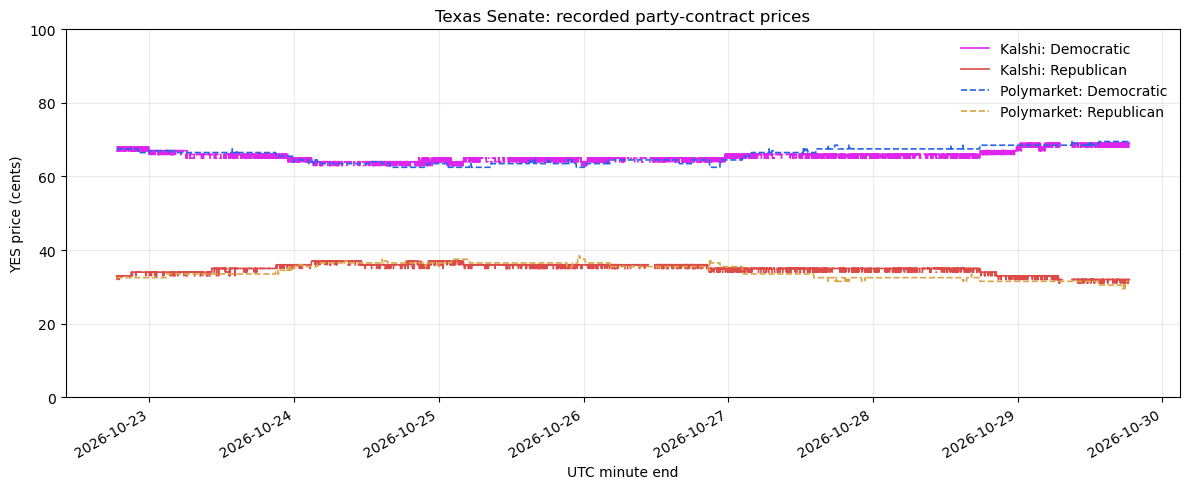

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
styles = {
    "kalshi_democratic": ("#de25eb", "-"),
    "kalshi_republican": ("#dc4b47", "-"),
    "polymarket_democratic": ("#2563eb", "--"),
    "polymarket_republican": ("#dca547", "--"),
}
for column, (color, linestyle) in styles.items():
    ax.plot(
        df["time"], df[column] * 100, label=LABELS[column],
        color=color, linestyle=linestyle, linewidth=1.2,
    )
ax.set(
    title="Texas Senate: recorded party-contract prices",
    xlabel="UTC minute end", ylabel="YES price (cents)", ylim=(0, 100),
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Rounding assumption

For the comparisons, we assume buyer-facing Polymarket prices are rounded up to
the next whole cent in the platform's favour. We apply this assumption before
calculating sums and price differences. This is our modelling assumption about
displayed prices. Missing values stay missing.


In [17]:
# Remove floating-point noise at exact cent boundaries before rounding upward.
prices_in_cents = (df[POLYMARKET_COLUMNS] * 100).round(10)
df[POLYMARKET_COLUMNS] = np.ceil(prices_in_cents) / 100


## Pair sums and cross-platform differences

Each sum combines a Republican YES price and a Democratic YES price, either on
the same platform or across platforms. Missing input prices produce missing sums.
A sum below $1 is a descriptive flag under the rounding assumption above.

For each party, the difference is **Kalshi minus Polymarket**. A positive value
means the recorded Kalshi price is higher; a negative value means it is lower.
The mean for each party uses its own available paired minutes, reported in the
summary table.


In [18]:
df["sum_kalshi"] = df["kalshi_republican"] + df["kalshi_democratic"]
df["sum_polymarket"] = df["polymarket_republican"] + df["polymarket_democratic"]
df["sum_kalshi_r_poly_d"] = df["kalshi_republican"] + df["polymarket_democratic"]
df["sum_poly_r_kalshi_d"] = df["polymarket_republican"] + df["kalshi_democratic"]

df["delta_republican"] = df["kalshi_republican"] - df["polymarket_republican"]
df["delta_democratic"] = df["kalshi_democratic"] - df["polymarket_democratic"]


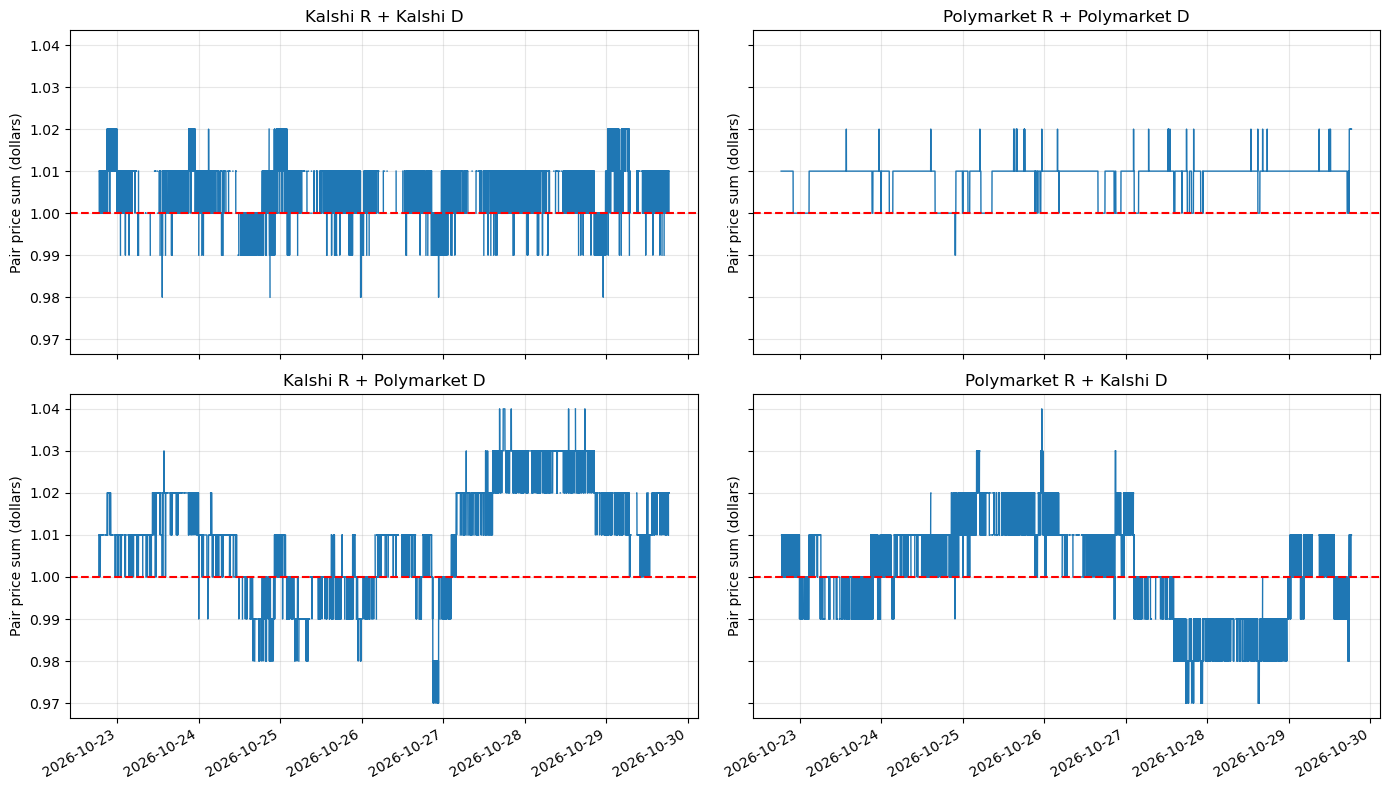

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

for ax, column in zip(axes.flat, SUM_COLUMNS):
    ax.plot(df["time"], df[column], linewidth=1)
    ax.axhline(y=1, color="red", linestyle="--")
    ax.set_title(textwrap.fill(LABELS[column], width=35))
    ax.set_ylabel("Pair price sum (dollars)")
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


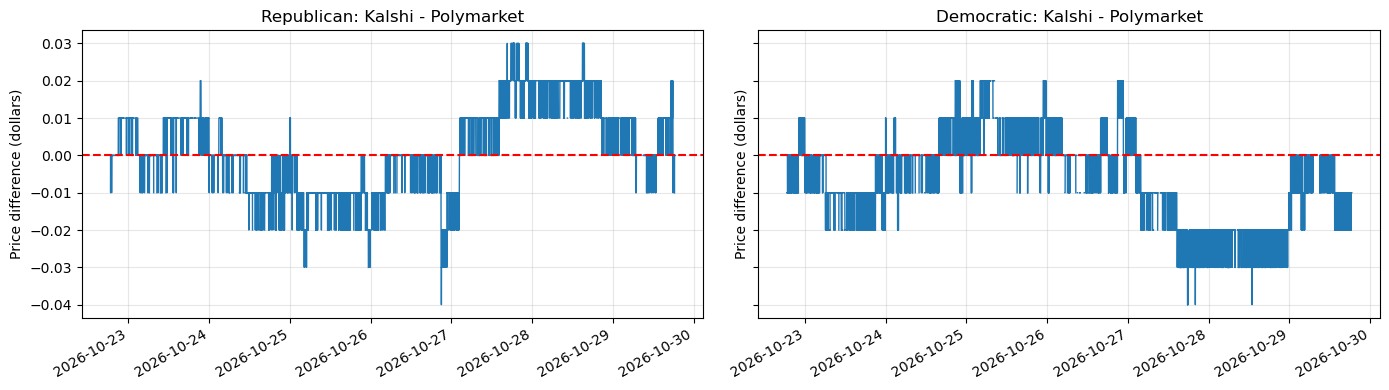

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)

for ax, column in zip(axes.flat, DELTA_COLUMNS):
    ax.plot(df["time"], df[column], linewidth=1)
    ax.axhline(y=0, color="red", linestyle="--")
    ax.set_title(textwrap.fill(LABELS[column], width=35))
    ax.set_ylabel("Price difference (dollars)")
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [21]:
difference_summary = pd.DataFrame({
    "mean_difference_cents": df[DELTA_COLUMNS].mean() * 100,
    "paired_minutes": df[DELTA_COLUMNS].count(),
})
display(difference_summary.rename(index=LABELS).round(3))


,mean_difference_cents,paired_minutes
Republican: Kalshi - Polymarket,0.345,8290
Democratic: Kalshi - Polymarket,-0.535,7266


## Frequency and duration of sums below $1

`minutes_below_1` counts observed minutes, not separate spells. The percentage
uses the number of minutes with both prices available as its denominator.
`missing_minutes` reports minutes excluded from that comparison.

A spell begins at the first observed sum below 1 and completes when the sum
reaches **1 or more**. Its duration is the elapsed time in minutes between those
timestamps. A missing price or a gap in the minute grid interrupts an active
spell; observations after the gap begin a new spell if they are below 1.

We report completed spells, interrupted spells, and spells still open at the
end separately. The average includes only completed spells. These are durations
of observed spells within our sample: a spell already underway at the start of
the sample or after a gap can have an earlier, unobserved beginning. Longer
unfinished spells are excluded from the average, so the result describes the
completed spells rather than the lifetime of all possible price differences.


In [22]:
def summarize_spells(prices):
    start = None
    previous_time = None
    durations = []
    interrupted = 0

    for timestamp, price in prices.items():
        gap = (
            previous_time is not None
            and timestamp - previous_time != pd.Timedelta(minutes=1)
        )
        if gap and start is not None:
            interrupted += 1
            start = None

        if pd.isna(price):
            if start is not None:
                interrupted += 1
            start = None
        elif price < 1:
            if start is None:
                start = timestamp
        elif start is not None:
            durations.append((timestamp - start).total_seconds() / 60)
            start = None
        previous_time = timestamp

    return {
        "completed_spells": len(durations),
        "interrupted_spells": interrupted,
        "open_at_end": int(start is not None),
        "mean_completed_minutes": np.mean(durations) if durations else np.nan,
    }


combination_data = df.set_index("time").loc[:, SUM_COLUMNS]
analysis = pd.DataFrame({
    "observed_minutes": combination_data.count(),
    "missing_minutes": combination_data.isna().sum(),
    "minutes_below_1": (combination_data < 1).sum(),
})
analysis["pct_below_1"] = (
    analysis["minutes_below_1"] / analysis["observed_minutes"] * 100
)
spell_stats = pd.DataFrame(
    [summarize_spells(combination_data[column]) for column in SUM_COLUMNS],
    index=SUM_COLUMNS,
)
analysis = analysis.join(spell_stats)
display(analysis.rename(index=LABELS).round(2))


,observed_minutes,missing_minutes,minutes_below_1,pct_below_1,completed_spells,interrupted_spells,open_at_end,mean_completed_minutes
Kalshi R + Kalshi D,6450,3630,297,4.60,161,69,0,1.27
Polymarket R + Polymarket D,10074,6,10,0.10,1,0,0,10.00
Kalshi R + Polymarket D,8289,1791,774,9.34,134,78,0,2.49
Polymarket R + Kalshi D,7266,2814,1997,27.48,178,362,0,1.42


## Exporting

The CSV contains the party-labelled columns and the upward-rounded Polymarket
prices used in the comparisons. Timestamps retain their explicit UTC offsets.
Each run writes a separate timestamped file.


In [ ]:
export_stamp = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S_%fZ")
csv_path = Path(f"texas_senate_consolidated_{export_stamp}.csv")
df.to_csv(csv_path, index=False, mode="x")
print(f"Saved {csv_path.resolve()}")
